In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
class LinearRegression:
    def __init__(self, learning_rate=0.01, max_iter=1000, standardize=True):
        self.learning_rate = learning_rate
        self.max_iter = max_iter
        self.standardize = standardize

        self.weights = None
        self.bias = 0
        self.loss_history = []

        self.mean = None
        self.std = None
    def fit(self, X, y):
        if self.standardize:
            self.mean = X.mean(axis=0)
            self.std = X.std(axis=0)
            self.std[self.std==0] = 1
            X = (X - self.mean) / self.std

        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0
        self.loss_history = []

        for _ in range(self.max_iter):
            y_pred = X @ self.weights + self.bias
            errors = y_pred - y
            loss = np.mean(errors ** 2)
            self.loss_history.append(loss)

            grad_w = (2 / n_samples) * (X.T @ errors)
            grad_b = (2 / n_samples) * np.sum(errors)
            self.weights -= self.learning_rate * grad_w
            self.bias -= self.learning_rate * grad_b

    def predict(self, X):
        if self.standardize:
            X = (X - self.mean) / self.std

        return X @ self.weights + self.bias

    @staticmethod
    def mse(y_pred, y_true):
        return np.mean((y_pred - y_true)**2)

    @staticmethod
    def mae(y_pred, y_true):
        return np.mean(np.abs(y_pred - y_true))

    @staticmethod
    def rmse(y_pred, y_true):
        return np.sqrt(np.mean((y_pred - y_true)**2))

    @staticmethod
    def r2(y_pred, y_true):
        return 1 - ((y_pred - y_true)**2).sum() / ((np.mean(y_true) - y_true)**2).sum()

**Проверка:** $y=3x+5$

Полученные оценки: 
 weights: [2.97623059] 
 bias: 5.198342410578632


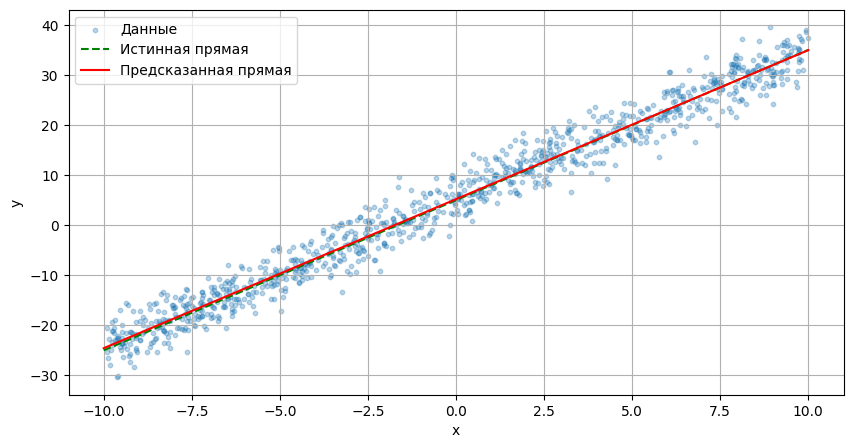

In [ ]:
np.random.seed(42)

X = np.random.uniform(-10, 10, 1000).reshape(-1, 1)
y = 3 * X.ravel() + 5 + np.random.normal(0, 3, 1000)

model = LinearRegression(learning_rate=0.01, max_iter=200, standardize=False)
model.fit(X, y)
print(f"Полученные оценки: \n weights: {model.weights} \n bias: {model.bias}")

X_line = np.linspace(-10, 10, 100).reshape(-1, 1)
y_pred = model.predict(X_line)
y_true = 3 * X_line.ravel() + 5

plt.figure(figsize=(10, 5))

plt.scatter(X, y, s=10, alpha=0.3, label='Данные')
plt.plot(X_line, y_true, 'g--', label='Истинная прямая')
plt.plot(X_line, y_pred, 'r', label='Предсказанная прямая')

plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid()
plt.show()

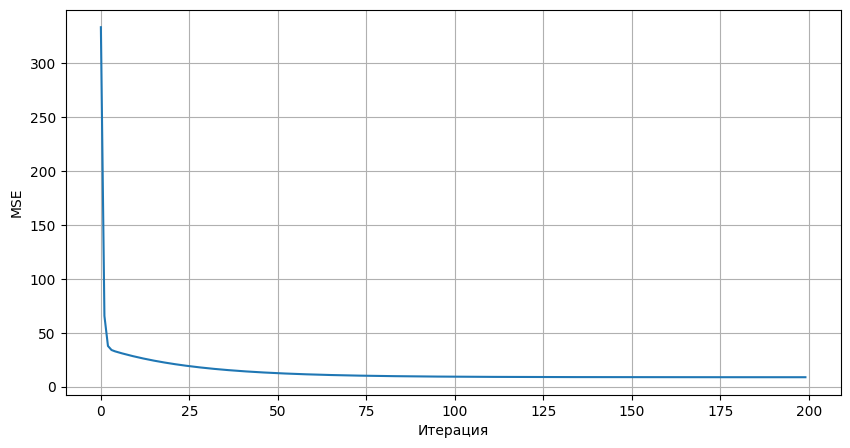

MSE: 8.783503463340951
MAE: 2.361733502678516
RMSE: 2.963697599847351
R2: 0.9717548859801081


In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(model.loss_history)

plt.xlabel('Итерация')
plt.ylabel('MSE')
plt.grid()
plt.show()

print('MSE:', model.mse(model.predict(X), y))
print('MAE:', model.mae(model.predict(X), y))
print('RMSE:', model.rmse(model.predict(X), y))
print('R2:', model.r2(model.predict(X), y))